<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone%204/Active_learning_and_human_in_the_loop_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 4, Section 2.4: Active learning and human-in-the-loop simulations

Two simulations, both using the continual-learning strategy of Section 1: each candidate X-learner is retrained from scratch on the new labelled users plus a 200,000-row replay buffer (the curation simulation retrains on the whole corrected subset), and replaces the deployed model only if the paired bootstrap gate on 250,000 random-holdout users (100 resamples) gives a Qini gain whose lower bound is above zero. Both the candidate's test Qini (what the update would achieve) and the deployed model's (what the gate lets through) are reported.

1. **Active learning.** Start from 5% of the training split; add 5% per cycle for five cycles, chosen at random or with the hybrid query strategy (uncertainty |tau0 - tau1|, margin to the profitability threshold, diversity across 50 feature-space clusters; weights 0.5 / 0.3 / 0.2). Criteo's randomized outcomes play the role of the experiment results. Set `DRIFT = 2.0` to run the same comparison with all raw features shifted by +2 sd.
2. **Human label curation.** A bot attack adds fake conversions (40% on top of the real ones) to treated users of one cluster in a random 30% subset of the training split. Annotators (95% detection, 2% false flags) review 15% of the conversions per cycle for three cycles, either at random or in the clusters with the most abnormal treated-control gap.

The code is in `uplift_pipeline/hitl.py`. Run all cells (about 30-40 minutes on a Colab CPU runtime). Results are written to `outputs/hitl/`.

In [1]:
# SETUP: install the XGBoost version the saved model was written with, and make the pipeline importable.
# The package is looked for (1) next to this notebook, (2) in an uploaded Milestone_4_code.zip,
# (3) in a clone of the GitHub repository (pulled again if it already exists).
%pip install -q xgboost==3.4.1 psutil
import os, sys, glob, zipfile, subprocess
PKG = None
if os.path.isdir("uplift_pipeline"):
    PKG = "."
if PKG is None and glob.glob("Milestone_4_code*.zip"):
    zipfile.ZipFile(sorted(glob.glob("Milestone_4_code*.zip"))[-1]).extractall(".")
    PKG = "Milestone 4"
if PKG is None:
    if os.path.isdir("INSE-6450"):
        subprocess.run(["git", "-C", "INSE-6450", "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/saopa28/INSE-6450.git"], check=True)
    PKG = os.path.join("INSE-6450", "Milestone 4")
if not os.path.isdir(os.path.join(PKG, "uplift_pipeline")):
    raise FileNotFoundError(f"uplift_pipeline not found in {PKG!r}. Push the 'Milestone 4' folder to GitHub, "
                            "or upload Milestone_4_code.zip to the Colab file panel and run this cell again.")
sys.path.insert(0, os.path.abspath(PKG))
import xgboost; print("xgboost", xgboost.__version__, "| pipeline from", os.path.abspath(PKG))

xgboost 3.4.1 | pipeline from /content/INSE-6450/Milestone 4


In [2]:
import numpy as np, pandas as pd
from IPython.display import display
from uplift_pipeline import load_data, split, load_v1, OUT_DIR
from uplift_pipeline.hitl import active_learning, label_curation, plot_active_learning, plot_label_curation, AL, CURATION

FRAC, DATA = 1.0, None
DRIFT = 0.0                     # 0 = original data; 2.0 = all raw features shifted by +2 sd
OUT = OUT_DIR / "hitl"; OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 250)

df = load_data(frac=FRAC) if DATA is None else load_data(DATA, frac=FRAC)
sp = split(df); del df
v1 = load_v1()                  # only its Milestone 2 configuration is used; every model here is trained from scratch
print({k: f"{len(v[2]):,} rows" for k, v in sp.items()})
display(pd.DataFrame({"active learning": pd.Series(AL), "label curation": pd.Series(CURATION)}))

{'train': '9,785,714 rows', 'val': '2,096,939 rows', 'test': '2,096,939 rows'}


,active learning,label curation
batch_frac,0.050,NaN
buffer_size,200000.000,NaN
cycles,NaN,3.00
fake_share,NaN,0.40
false_flag,NaN,0.02
gate_boot,100.000,NaN
gate_rows,250000.000,NaN
hit_rate,NaN,0.95
init_frac,0.050,NaN
n_clusters,50.000,NaN


## 1. Active learning with continual updates

In [3]:
al, al_summ = active_learning(sp, clf=v1.clf, reg=v1.reg, drift_k=DRIFT)
al.to_csv(OUT / "active_learning.csv", index=False); al_summ.to_csv(OUT / "active_learning_summary.csv")
display(al.round(6))
display(al_summ)

  random           cycle 0: 489,285 users | candidate Qini +0.000290 | deployed +0.000290 | gate [+nan, +nan]
  random           cycle 1: 978,570 users | candidate Qini +0.000339 | deployed +0.000290 | gate [-0.000296, +0.000175]
  random           cycle 2: 1,467,855 users | candidate Qini +0.000310 | deployed +0.000290 | gate [-0.000067, +0.000391]
  random           cycle 3: 1,957,140 users | candidate Qini +0.000372 | deployed +0.000290 | gate [-0.000284, +0.000138]
  random           cycle 4: 2,446,425 users | candidate Qini +0.000336 | deployed +0.000290 | gate [-0.000232, +0.000149]
  random           cycle 5: 2,935,710 users | candidate Qini +0.000319 | deployed +0.000290 | gate [-0.000144, +0.000290]
  active (hybrid)  cycle 0: 489,285 users | candidate Qini +0.000290 | deployed +0.000290 | gate [+nan, +nan]
  active (hybrid)  cycle 1: 978,570 users | candidate Qini +0.000383 | deployed +0.000290 | gate [-0.000199, +0.000163]
  active (hybrid)  cycle 2: 1,467,855 users | candid

,strategy,cycle,labeled_users,candidate_qini,candidate_uplift10,promoted,gate_ci_lo,gate_ci_hi,deployed_qini,deployed_uplift10,scoring_trees,scoring_us_per_user_batch,update_s
0,random,0,489285,0.000290,0.007154,None,NaN,NaN,0.00029,0.007154,38,0.781,0.0
1,random,1,978570,0.000339,0.007466,False,-0.000296,0.000175,0.00029,0.007154,38,0.883,51.1
2,random,2,1467855,0.000310,0.007274,False,-0.000067,0.000391,0.00029,0.007154,38,0.781,47.7
3,random,3,1957140,0.000372,0.007698,False,-0.000284,0.000138,0.00029,0.007154,38,0.795,48.9
4,random,4,2446425,0.000336,0.007618,False,-0.000232,0.000149,0.00029,0.007154,38,0.790,47.0
5,random,5,2935710,0.000319,0.007326,False,-0.000144,0.000290,0.00029,0.007154,38,0.790,48.6
6,active (hybrid),0,489285,0.000290,0.007154,None,NaN,NaN,0.00029,0.007154,38,0.916,0.0
7,active (hybrid),1,978570,0.000383,0.008008,False,-0.000199,0.000163,0.00029,0.007154,38,0.783,49.2
8,active (hybrid),2,1467855,0.000385,0.007877,False,-0.000263,0.000164,0.00029,0.007154,38,0.780,85.0
9,active (hybrid),3,1957140,0.000377,0.008263,False,-0.000274,0.000139,0.00029,0.007154,38,0.784,74.4


strategy,random,active (hybrid)
final_candidate_qini,0.000319,0.000317
mean_candidate_qini,0.000335,0.000364
final_deployed_qini,0.00029,0.00029
promotions,0/5,0/5
deployed_top10_overlap,1.0,1.0
candidate_top10_overlap,0.71722,0.66694
final_scoring_trees,38,38
final_scoring_us_per_user_batch,0.79,0.783
mean_update_s,48.66,65.84


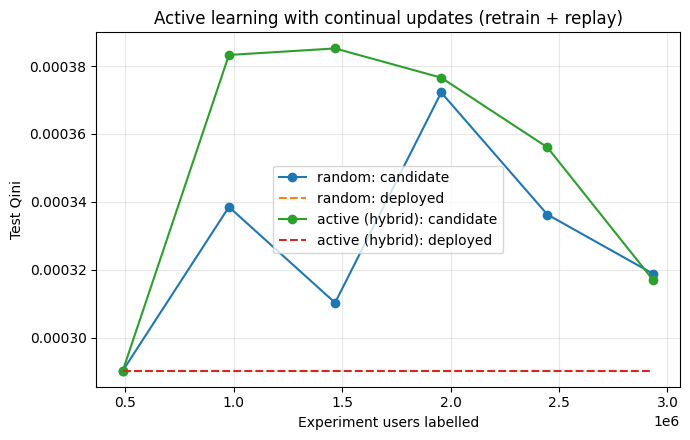

In [4]:
fig = plot_active_learning(al, OUT / "active_learning.png")

## 2. Human label curation with continual updates

In [5]:
hc, hc_summ, info = label_curation(sp, clf=v1.clf, reg=v1.reg)
hc.to_csv(OUT / "label_curation.csv", index=False); hc_summ.to_csv(OUT / "label_curation_summary.csv")
print(f"{info['fakes']:,} fake conversions added to {info['real_conversions']:,} real ones | clean-label Qini "
      f"{info['clean_qini']:.6f} | before curation {info['noisy_qini']:.6f} ({100 * info['noisy_qini'] / info['clean_qini']:.0f}% of clean)")
display(hc.round(6))
display(hc_summ)

  3,397 fake conversions added to 8,493 real ones (cluster 32); clean-label Qini 0.000379
  random review    cycle 0: reviewed 0 | fakes left 3,397 | candidate 89.5% of clean
  random review    cycle 1: reviewed 1,783 | fakes left 2,883 | candidate 97.1% of clean
  random review    cycle 2: reviewed 3,566 | fakes left 2,346 | candidate 98.2% of clean
  random review    cycle 3: reviewed 5,349 | fakes left 1,848 | candidate 102.6% of clean
  targeted review  cycle 0: reviewed 0 | fakes left 3,397 | candidate 89.5% of clean
  targeted review  cycle 1: reviewed 1,783 | fakes left 1,724 | candidate 100.3% of clean
  targeted review  cycle 2: reviewed 3,566 | fakes left 180 | candidate 103.0% of clean
  targeted review  cycle 3: reviewed 5,349 | fakes left 180 | candidate 96.0% of clean
3,397 fake conversions added to 8,493 real ones | clean-label Qini 0.000379 | before curation 0.000340 (89% of clean)


,strategy,cycle,reviewed_conversions,fakes_left,candidate_qini,candidate_pct_of_clean,promoted,gate_ci_lo,gate_ci_hi,deployed_qini,deployed_pct_of_clean,deployed_uplift10,update_s
0,random review,0,0,3397,0.000340,89.484218,None,NaN,NaN,0.00034,89.484218,0.006952,0.0
1,random review,1,1783,2883,0.000368,97.071600,False,-0.000101,0.000063,0.00034,89.484218,0.006952,109.7
2,random review,2,3566,2346,0.000373,98.195077,False,-0.000142,0.000089,0.00034,89.484218,0.006952,131.2
3,random review,3,5349,1848,0.000389,102.633037,False,-0.000148,0.000091,0.00034,89.484218,0.006952,128.3
4,targeted review,0,0,3397,0.000340,89.484218,None,NaN,NaN,0.00034,89.484218,0.006952,0.0
5,targeted review,1,1783,1724,0.000381,100.274543,False,-0.000155,0.000092,0.00034,89.484218,0.006952,128.8
6,targeted review,2,3566,180,0.000391,103.013860,False,-0.000244,0.000047,0.00034,89.484218,0.006952,124.0
7,targeted review,3,5349,180,0.000364,95.983169,False,-0.000152,0.000089,0.00034,89.484218,0.006952,141.1


strategy,random review,targeted review
final_candidate_pct_of_clean,102.633037,95.983169
final_deployed_pct_of_clean,89.484218,89.484218
fakes_removed_pct,45.599058,94.701207
reviews_to_remove_90pct_fakes,not reached,3566
pct_of_conversions_reviewed_then,-,30%
promotions,0/3,0/3
deployed_rank_corr_between_cycles,1.0,1.0
deployed_top10_overlap_between_cycles,1.0,1.0


Files written: ['active_learning.csv', 'active_learning.png', 'active_learning_summary.csv', 'label_curation.csv', 'label_curation.png', 'label_curation_summary.csv']


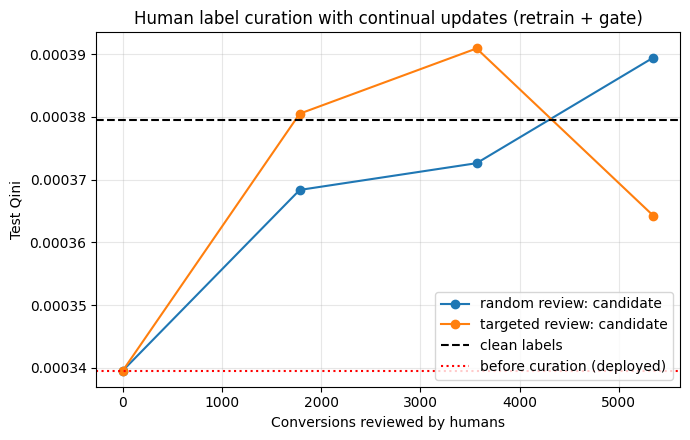

In [6]:
fig = plot_label_curation(hc, info, OUT / "label_curation.png")
print("Files written:", sorted(p.name for p in OUT.iterdir()))